In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load datasets
fake = pd.read_csv("Fake.csv")
true = pd.read_csv("True.csv")

# Add labels
fake["label"] = 0
true["label"] = 1

# Combine datasets
data = pd.concat([fake, true], ignore_index=True)

# Shuffle data
data = data.sample(frac=1, random_state=42).reset_index(drop=True)

print("Fake news:", len(fake))
print("Real news:", len(true))
print("Total articles:", len(data))

data.head()

Fake news: 23481
Real news: 21417
Total articles: 44898


,title,text,subject,date,label
0,Ben Stein Calls Out 9th Circuit Court: Committ...,"21st Century Wire says Ben Stein, reputable pr...",US_News,"February 13, 2017",0
1,Trump drops Steve Bannon from National Securit...,WASHINGTON (Reuters) - U.S. President Donald T...,politicsNews,"April 5, 2017",1
2,Puerto Rico expects U.S. to lift Jones Act shi...,(Reuters) - Puerto Rico Governor Ricardo Rosse...,politicsNews,"September 27, 2017",1
3,OOPS: Trump Just Accidentally Confirmed He Le...,"On Monday, Donald Trump once again embarrassed...",News,"May 22, 2017",0
4,Donald Trump heads for Scotland to reopen a go...,"GLASGOW, Scotland (Reuters) - Most U.S. presid...",politicsNews,"June 24, 2016",1


In [2]:
# CLEANING DATA
print("Dataset Shape:", data.shape)
print("\nMissing Values:")
print(data.isnull().sum())

# Remove duplicate rows
data = data.drop_duplicates()

print("\nDuplicates after removal:", data.duplicated().sum())

# Create text length feature
data["text_length"] = data["text"].astype(str).apply(len)

# Display basic statistics
print("\nText Length Statistics:")
print(data["text_length"].describe())

Dataset Shape: (44898, 5)

Missing Values:
title      0
text       0
subject    0
date       0
label      0
dtype: int64

Duplicates after removal: 0

Text Length Statistics:
count    44689.000000
mean      2467.098682
std       2173.612347
min          1.000000
25%       1232.000000
50%       2185.000000
75%       3101.000000
max      51794.000000
Name: text_length, dtype: float64


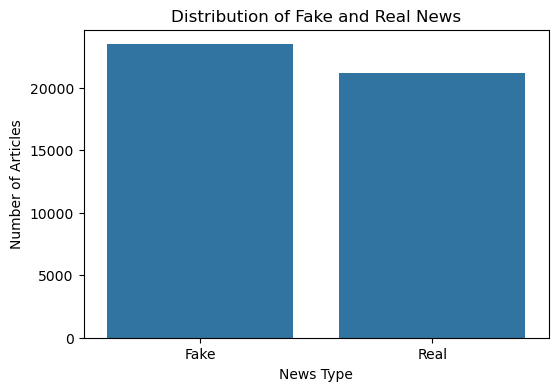

In [3]:

# Graph 1: Fake vs Real
plt.figure(figsize=(6,4))
sns.countplot(x="label", data=data)
plt.title("Distribution of Fake and Real News")
plt.xlabel("News Type")
plt.ylabel("Number of Articles")
plt.xticks([0,1], ["Fake", "Real"])
plt.show()

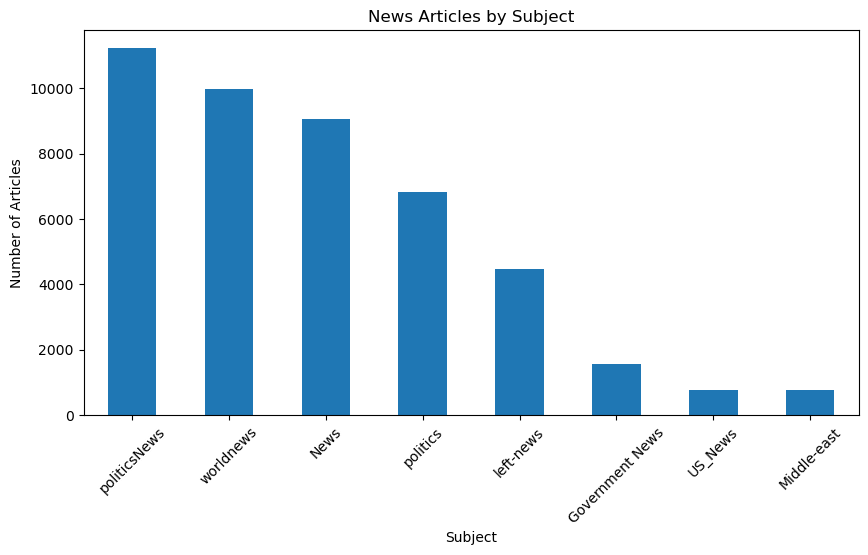


Updated Dataset Shape: (44689, 6)


In [4]:
# Graph 2: News by Subject
plt.figure(figsize=(10,5))
data["subject"].value_counts().plot(kind="bar")
plt.title("News Articles by Subject")
plt.xlabel("Subject")
plt.ylabel("Number of Articles")
plt.xticks(rotation=45)
plt.show()
# Show updated dataset information
print("\nUpdated Dataset Shape:", data.shape)

In [5]:
#TEXT PREPROCESSING
import re
# Combine title and article text
data["content"] = (
    data["title"].fillna("") + " " +
    data["text"].fillna("")
)
# Text cleaning function
def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)
    text = re.sub(r"[^a-zA-Z\s]", "", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

# Apply preprocessing
data["clean_content"] = data["content"].apply(clean_text)

# Remove empty records
data = data[data["clean_content"].str.strip() != ""]

print("Text preprocessing completed.")

# Show before and after
print("\nOriginal:")
print(data["content"].iloc[0][:300])

print("\nCleaned:")
print(data["clean_content"].iloc[0][:300])

Text preprocessing completed.

Original:
Ben Stein Calls Out 9th Circuit Court: Committed a ‘Coup d’état’ Against the Constitution 21st Century Wire says Ben Stein, reputable professor from, Pepperdine University (also of some Hollywood fame appearing in TV shows and films such as Ferris Bueller s Day Off) made some provocative statements 

Cleaned:
ben stein calls out th circuit court committed a coup dtat against the constitution st century wire says ben stein reputable professor from pepperdine university also of some hollywood fame appearing in tv shows and films such as ferris bueller s day off made some provocative statements on judge jea


In [9]:
#TRAIN/TEST SPLIT
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# Input and target
X = data["clean_content"]
y = data["label"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


In [8]:
# TF-IDF feature extraction
tfidf = TfidfVectorizer(
    max_features=50000,
    stop_words="english",
    ngram_range=(1,2)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training data:", X_train_tfidf.shape)
print("Testing data:", X_test_tfidf.shape)

Training data: (35744, 50000)
Testing data: (8936, 50000)


In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

# Create models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Naive Bayes": MultinomialNB(),
    "Linear SVM": LinearSVC()
}

# Train models
for name, model in models.items():
    model.fit(X_train_tfidf, y_train)

print("All models trained successfully!")

All models trained successfully!


In [11]:
#ACCURACY,RECALL AND PERCISION
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

results = []

for name, model in models.items():

    y_pred = model.predict(X_test_tfidf)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    results.append([
        name,
        accuracy,
        precision,
        recall,
        f1
    ])

    print("\n" + "="*50)
    print(name)
    print("="*50)
    print(classification_report(
        y_test,
        y_pred,
        target_names=["Fake", "Real"]
    ))

results_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ]
)

print("\nMODEL COMPARISON")
print(results_df)


Logistic Regression
              precision    recall  f1-score   support

        Fake       0.99      0.99      0.99      4694
        Real       0.99      0.99      0.99      4242

    accuracy                           0.99      8936
   macro avg       0.99      0.99      0.99      8936
weighted avg       0.99      0.99      0.99      8936


Naive Bayes
              precision    recall  f1-score   support

        Fake       0.96      0.96      0.96      4694
        Real       0.95      0.96      0.95      4242

    accuracy                           0.96      8936
   macro avg       0.96      0.96      0.96      8936
weighted avg       0.96      0.96      0.96      8936


Linear SVM
              precision    recall  f1-score   support

        Fake       1.00      1.00      1.00      4694
        Real       1.00      1.00      1.00      4242

    accuracy                           1.00      8936
   macro avg       1.00      1.00      1.00      8936
weighted avg       1.00     

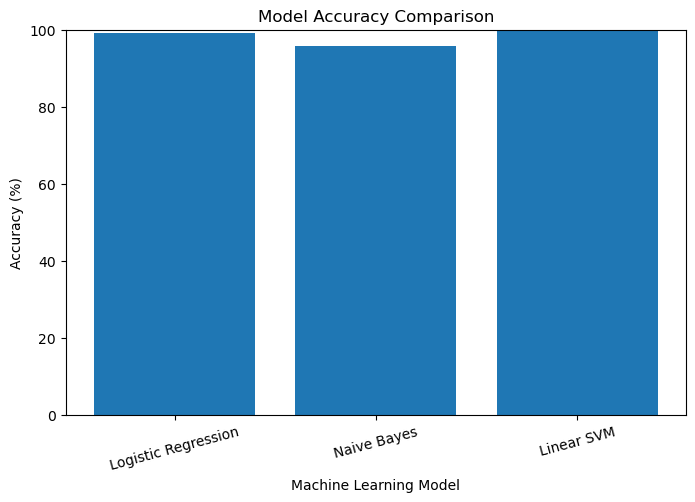

Selected model: Linear SVM


In [12]:
#MODEL COMPARISION GRAPH
# Convert scores to percentage
plot_df = results_df.copy()

for column in ["Accuracy", "Precision", "Recall", "F1-Score"]:
    plot_df[column] = plot_df[column] * 100

# Accuracy comparison
plt.figure(figsize=(8,5))
plt.bar(plot_df["Model"], plot_df["Accuracy"])
plt.title("Model Accuracy Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy (%)")
plt.ylim(0,100)
plt.xticks(rotation=15)
plt.show()

# Find model with highest accuracy
best_model_name = results_df.loc[
    results_df["Accuracy"].idxmax(), "Model"
]

best_model = models[best_model_name]

print("Selected model:", best_model_name)

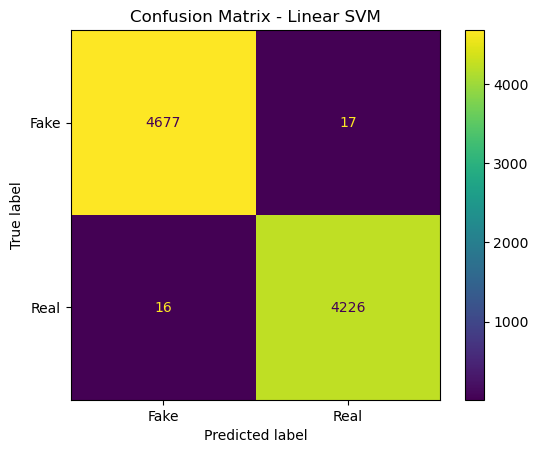

In [13]:
#CONFUSION MATRIX
from sklearn.metrics import ConfusionMatrixDisplay

y_best_pred = best_model.predict(X_test_tfidf)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_best_pred,
    display_labels=["Fake", "Real"]
)

plt.title("Confusion Matrix - " + best_model_name)
plt.show()

In [15]:
#TESTING
news = input("Enter a news article: ")
clean_news = clean_text(news)
news_tfidf = tfidf.transform([clean_news])
prediction = best_model.predict(news_tfidf)[0]
if prediction == 0:
    print("\nPrediction: FAKE NEWS")
else:
    print("\nPrediction: REAL NEWS")

Enter a news article:  Donald Trump just couldn t wish all Americans a Happy New Year and leave it at that. Instead, he had to give a shout out to his enemies, haters and  the very dishonest fake news media.  The former reality show star had just one job to do and he couldn t do it. As our Country rapidly grows stronger and smarter, I want to wish all of my friends, supporters, enemies, haters, and even the very dishonest Fake News Media, a Happy and Healthy New Year,  President Angry Pants tweeted.  2018 will be a great year for America! As our Country rapidly grows stronger and smarter, I want to wish all of my friends, supporters, enemies, haters, and even the very dishonest Fake News Media, a Happy and Healthy New Year. 2018 will be a great year for America!  Donald J. Trump (@realDonaldTrump) December 31, 2017Trump s tweet went down about as welll as you d expect.What kind of president sends a New Year s greeting like this despicable, petty, infantile gibberish? Only Trump! His la


Prediction: FAKE NEWS


In [16]:
#SAVE TRAINED MODELS
import joblib
joblib.dump(best_model, "fake_news_model.pkl")
joblib.dump(tfidf, "tfidf_vectorizer.pkl")
print("Model and TF-IDF vectorizer saved successfully!")

Model and TF-IDF vectorizer saved successfully!
